### 1. Setup Environment


In [8]:
import sys, json, joblib
from pathlib import Path

ROOT_DIR = Path(r"c:\Project\napasloka\napasloka")

if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))


In [9]:
import pandas as pd

summary_path = ROOT_DIR / "artifacts" / "summary_metrics.csv"
df_summary = pd.read_csv(summary_path)
df_summary

,location,pollutant,scenario,algorithm,mae,rmse,mape,r2,training_time_seconds,prediction_time_seconds,best_params
0,taman-kamal,CO,scenario_1,xgboost,63.622424,95.122871,6.227183,0.981961,9.730577,0.006736,"{'n_estimators': 300, 'max_depth': 6, 'learnin..."
1,taman-kamal,CO,scenario_1,lightgbm,62.475965,92.168714,6.145671,0.983064,5.649717,0.022104,"{'n_estimators': 500, 'max_depth': 9, 'learnin..."
2,taman-kamal,CO,scenario_2,xgboost,69.062951,100.652386,7.033787,0.979803,13.110022,0.006275,"{'n_estimators': 300, 'max_depth': 6, 'learnin..."
3,taman-kamal,CO,scenario_2,lightgbm,65.859890,96.135442,6.742276,0.981575,7.262533,0.021443,"{'n_estimators': 500, 'max_depth': 9, 'learnin..."
4,taman-kamal,CO2,scenario_1,xgboost,1.187560,1.654335,0.255770,0.982027,1.528648,0.006892,"{'n_estimators': 300, 'max_depth': 6, 'learnin..."
...,...,...,...,...,...,...,...,...,...,...,...
115,cibinong,CO,scenario_2,lightgbm,58.531201,82.637753,5.273384,0.981507,8.227737,0.021661,"{'n_estimators': 500, 'max_depth': 9, 'learnin..."
116,cibinong,CO2,scenario_1,xgboost,2.205892,3.112544,0.455648,0.985864,1.852382,0.006727,"{'n_estimators': 300, 'max_depth': 6, 'learnin..."
117,cibinong,CO2,scenario_1,lightgbm,2.127231,2.991223,0.439458,0.986944,4.850213,0.020659,"{'n_estimators': 500, 'max_depth': 9, 'learnin..."
118,cibinong,CO2,scenario_2,xgboost,2.216560,3.189861,0.456774,0.985152,10.274093,0.005932,"{'n_estimators': 300, 'max_depth': 6, 'learnin..."


### 2. Hasil Hyperparameter Tuning

In [3]:
df_tuning = df_summary.copy()
df_tuning["learning_rate"] = df_tuning["best_params"].str.extract(r"'learning_rate': ([0-9.]+)").astype(float)
df_tuning["n_estimators"] = df_tuning["best_params"].str.extract(r"'n_estimators': (\d+)").astype(int)
df_tuning["max_depth"] = df_tuning["best_params"].str.extract(r"'max_depth': (\d+)").astype(int)

tabel_tuning = df_tuning.groupby("algorithm")[["learning_rate", "n_estimators", "max_depth"]].first().reset_index()

tabel_tuning.columns = ["Algoritma", "Learning Rate", "N Estimators", "Max Depth"]
tabel_tuning["Algoritma"] = tabel_tuning["Algoritma"].str.upper()
display(tabel_tuning)

,Algoritma,Learning Rate,N Estimators,Max Depth
0,LIGHTGBM,0.05,500,9
1,XGBOOST,0.05,300,6


### 3. Ringkasan Global Performa Algoritma dan Skenario

In [4]:
df_global_summary = df_summary.groupby(["pollutant", "scenario", "algorithm"])[[
    "r2", "mae", "rmse", "mape", "training_time_seconds", "prediction_time_seconds"]].mean().reset_index()
df_global_summary = df_global_summary.round({"r2": 4, "mae": 2, "rmse": 2, "mape": 2})
display(df_global_summary)

,pollutant,scenario,algorithm,r2,mae,rmse,mape,training_time_seconds,prediction_time_seconds
0,CO,scenario_1,lightgbm,0.9790,90.20,132.10,7.15,5.297939,0.021117
1,CO,scenario_1,xgboost,0.9780,92.37,135.43,7.37,3.051475,0.006018
2,CO,scenario_2,lightgbm,0.9781,90.38,135.02,7.25,7.317046,0.021210
3,CO,scenario_2,xgboost,0.9761,94.06,140.76,7.56,11.413674,0.006077
4,CO2,scenario_1,lightgbm,0.9816,1.57,2.25,0.33,4.928275,0.021253
5,CO2,scenario_1,xgboost,0.9804,1.61,2.32,0.34,1.598812,0.006483
6,CO2,scenario_2,lightgbm,0.9815,1.57,2.25,0.33,6.982772,0.024036
7,CO2,scenario_2,xgboost,0.9794,1.64,2.37,0.35,10.391720,0.006165


### 4. Model Terbaik di 15 Lokasi

In [5]:
def get_champion_table(pollutant_code):
    sub = df_summary[df_summary["pollutant"] == pollutant_code].copy()

    best = sub.sort_values(["location", "mae"], ascending=True).groupby("location").first().reset_index()
    
    best = best[["location", "scenario", "algorithm", "r2", "mae", "rmse", "mape", "training_time_seconds", "prediction_time_seconds"]]
    best["r2"] = best["r2"].round(4)
    best["mae"] = best["mae"].round(2)
    best["rmse"] = best["rmse"].round(2)
    best["mape"] = best["mape"].round(2)
    best["training_time_seconds"] = best["training_time_seconds"].round(2)
    best["prediction_time_seconds"] = (best["prediction_time_seconds"] * 1000).round(2)
    
    best.columns = ["Lokasi Pengamatan", "Skenario", "Algoritma", "R²", "MAE", "RMSE", "MAPE (%)", "Waktu Latih (s)", "Waktu Uji (ms)"]
    return best
tabel_champion_co = get_champion_table("CO")
tabel_champion_co2 = get_champion_table("CO2")
display(tabel_champion_co)
display(tabel_champion_co2)

,Lokasi Pengamatan,Skenario,Algoritma,R²,MAE,RMSE,MAPE (%),Waktu Latih (s),Waktu Uji (ms)
0,cibinong,scenario_2,lightgbm,0.9815,58.53,82.64,5.27,8.23,21.66
1,daerah-pelabuhan-tanjung-priuk,scenario_1,lightgbm,0.9824,60.69,97.17,7.30,6.33,22.26
2,jl-tol-jagorawi,scenario_2,lightgbm,0.9814,81.65,117.41,6.69,8.84,22.83
3,kaliabang-tengah,scenario_2,lightgbm,0.9807,77.23,117.49,7.69,6.82,20.16
4,metland-cyberpuri,scenario_1,lightgbm,0.9746,113.37,162.52,7.03,4.69,20.47
5,mustikasari,scenario_2,lightgbm,0.9811,67.54,102.88,6.78,6.93,21.83
6,pancoran-mas,scenario_1,lightgbm,0.9815,89.71,127.74,6.15,6.14,24.03
7,pantai-makmur,scenario_2,lightgbm,0.9778,50.84,96.30,6.33,7.41,19.86
8,pelabuhan-muara-baru,scenario_1,lightgbm,0.9800,74.18,114.17,7.09,5.88,21.02
9,perumahan-dekat-tol-depok-antasari,scenario_2,lightgbm,0.9756,127.31,184.92,7.53,7.11,21.29


,Lokasi Pengamatan,Skenario,Algoritma,R²,MAE,RMSE,MAPE (%),Waktu Latih (s),Waktu Uji (ms)
0,cibinong,scenario_2,lightgbm,0.9872,2.07,2.96,0.43,7.36,21.55
1,daerah-pelabuhan-tanjung-priuk,scenario_1,lightgbm,0.9797,1.14,1.65,0.25,4.24,21.67
2,jl-tol-jagorawi,scenario_2,lightgbm,0.9839,1.68,2.30,0.35,6.85,22.74
3,kaliabang-tengah,scenario_2,lightgbm,0.9817,1.37,2.01,0.29,7.21,21.42
4,metland-cyberpuri,scenario_2,lightgbm,0.9794,1.52,2.14,0.32,7.47,22.92
5,mustikasari,scenario_2,lightgbm,0.9836,1.48,2.10,0.31,7.27,22.22
6,pancoran-mas,scenario_1,lightgbm,0.9856,1.89,2.68,0.39,4.47,21.30
7,pantai-makmur,scenario_2,lightgbm,0.9801,1.13,1.66,0.24,5.98,22.00
8,pelabuhan-muara-baru,scenario_1,lightgbm,0.9817,1.16,1.62,0.25,5.76,22.11
9,perumahan-dekat-tol-depok-antasari,scenario_1,lightgbm,0.9807,1.92,2.79,0.40,6.08,21.18


### 5. Kurva Deret Waktu Perbandingan Nilai Aktual dan Prediksi

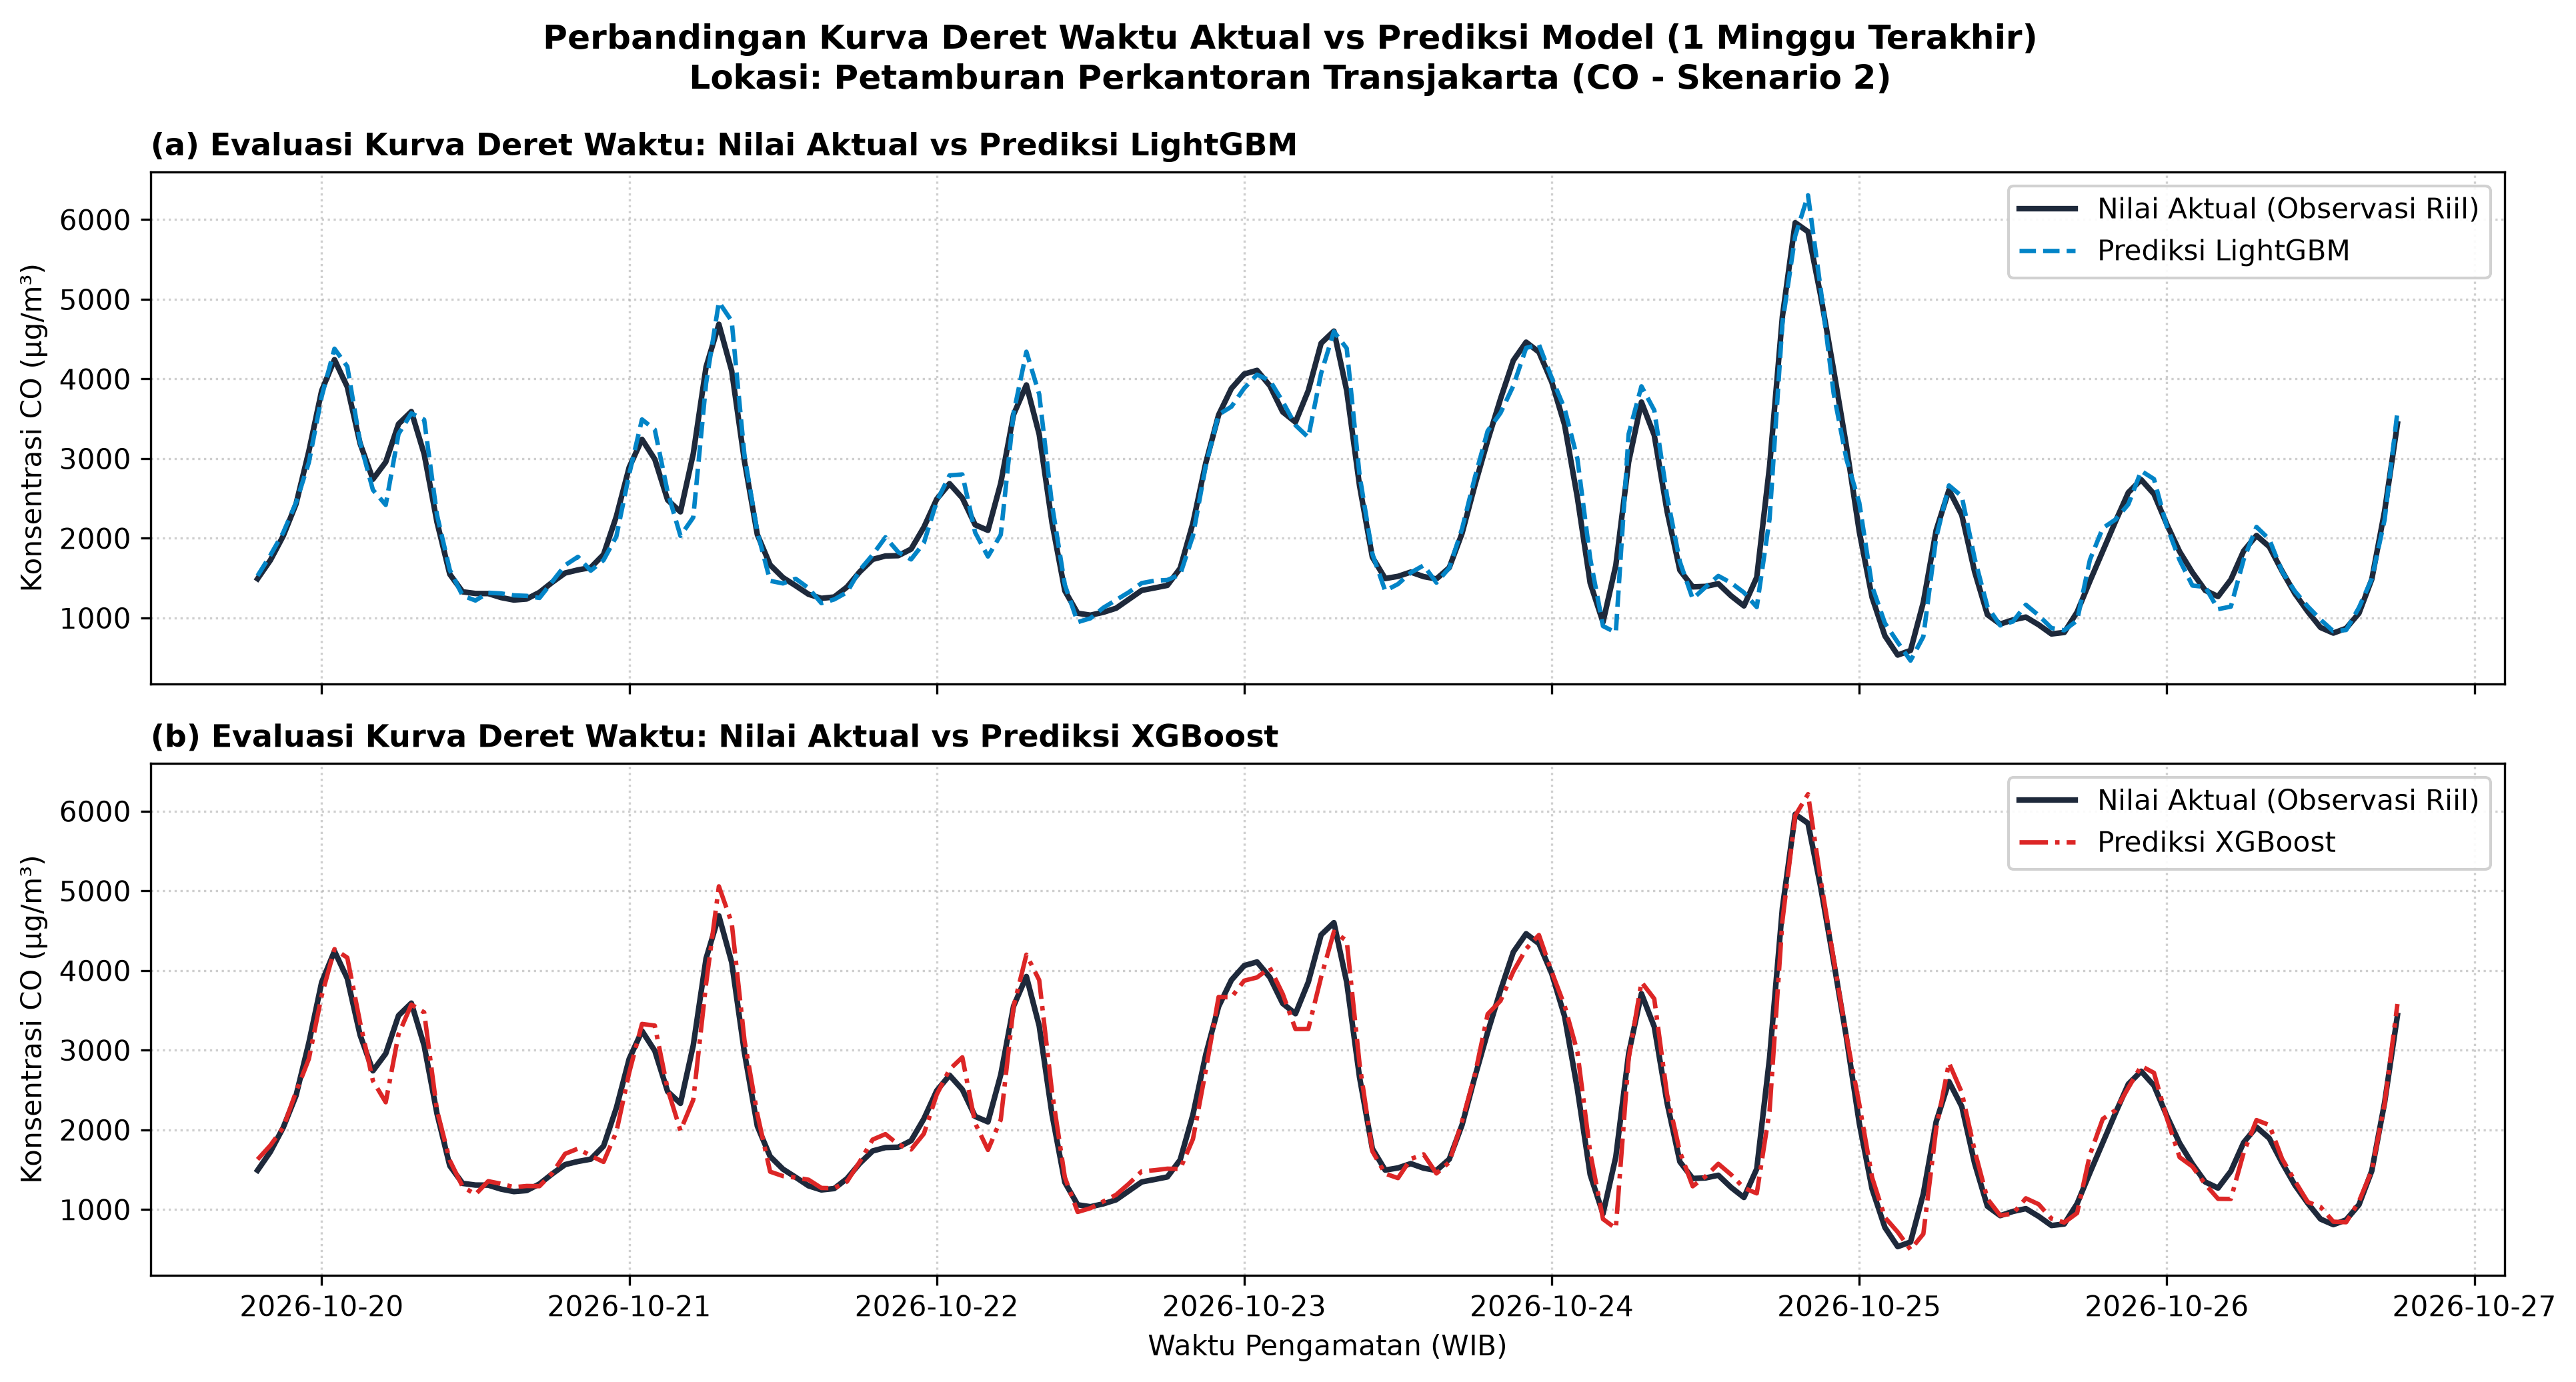

In [ ]:
import matplotlib.pyplot as plt

# 1. Pemuatan Data 
p_lgb = ROOT_DIR / "artifacts/experiments/petamburan-perkantoran-transjakarta/co/scenario_2/lightgbm/predictions.csv"
p_xgb = ROOT_DIR / "artifacts/experiments/petamburan-perkantoran-transjakarta/co/scenario_2/xgboost/predictions.csv"
df_lgb = pd.read_csv(p_lgb).tail(168).copy()
df_xgb = pd.read_csv(p_xgb).tail(168).copy()
df_lgb["datetime"] = pd.to_datetime(df_lgb["datetime"])
df_xgb["datetime"] = pd.to_datetime(df_xgb["datetime"])

# 2. Pembuatan 2 Panel Subplot Bertingkat
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 7), sharex=True, sharey=True, dpi=300)

# Panel (a): Aktual vs LightGBM
ax1.plot(df_lgb["datetime"], df_lgb["actual"], color="#1e293b", linewidth=2.0, label="Nilai Aktual (Observasi Riil)")
ax1.plot(df_lgb["datetime"], df_lgb["predicted"], color="#0284c7", linewidth=1.6, linestyle="--", label="Prediksi LightGBM")
ax1.set_title("(a) Evaluasi Kurva Deret Waktu: Nilai Aktual vs Prediksi LightGBM", fontsize=11, fontweight="bold", loc="left")
ax1.set_ylabel("Konsentrasi CO (µg/m³)", fontsize=10)
ax1.legend(loc="upper right", framealpha=0.9)
ax1.grid(True, linestyle=":", alpha=0.6)

# Panel (b): Aktual vs XGBoost
ax2.plot(df_xgb["datetime"], df_xgb["actual"], color="#1e293b", linewidth=2.0, label="Nilai Aktual (Observasi Riil)")
ax2.plot(df_xgb["datetime"], df_xgb["predicted"], color="#dc2626", linewidth=1.6, linestyle="-.", label="Prediksi XGBoost")
ax2.set_title("(b) Evaluasi Kurva Deret Waktu: Nilai Aktual vs Prediksi XGBoost", fontsize=11, fontweight="bold", loc="left")
ax2.set_xlabel("Waktu Pengamatan (WIB)", fontsize=10)
ax2.set_ylabel("Konsentrasi CO (µg/m³)", fontsize=10)
ax2.legend(loc="upper right", framealpha=0.9)
ax2.grid(True, linestyle=":", alpha=0.6)
plt.suptitle("Perbandingan Kurva Deret Waktu Aktual vs Prediksi Model (1 Minggu Terakhir)\nLokasi: Petamburan Perkantoran Transjakarta (CO - Skenario 2)", 
             fontsize=12, fontweight="bold", y=0.98)
plt.tight_layout()
plt.show()